<a href="https://colab.research.google.com/github/SergeiVKalinin/RL_and_Rewards/blob/main/RL_EELS/0_EELS_RL_Drift_Blur.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Autonomous EELS — Complete Drift, Blur, Calibration, and RL Study

**Reproducible Colab research notebook** based on the ATHENA hackathon's original `gdown` dataset opener. This notebook **computes results anew**, rather than replaying published plots. It includes (1) data provenance and full-data oracle, (2) static drift, 2-D autoencoder drift clouds and cross-model degradation, (3) the fixed-window scan-speed/blur response, (4) measured cross-correlation calibration, (5) drift models and eight instrument actions, (6) separate model-free RL rewards for response discovery and structure–property learning, (7) periodic / fixed / K1 / K2 / RL comparisons, (8) 300-unit evaluation campaigns with full telemetry and figure generation.

**Experimental source:** dataset `2` of `Plasmonic_sets_hackathon.npy`, via `gdown(id=...)` using the source notebook's file ID. No experimental spectra are fabricated. Simulated image drift and blur are explicitly modeled; missing spectroscopy labels are never treated as measured. The original data permit an offline *oracle* to evaluate measurements, but online policies are not given unmeasured labels or held-out test errors.

**Workload:** select `MODE = 'LIGHT'` for a functional pilot or `MODE = 'FULL'` for 300-unit, multi-seed Colab study. Running FULL may require hours, especially when model-free RL uses repeated Random Forest updates. CPU/GPU times are hardware dependent.

**Differences from archived studies:** this is one consistent, standalone rerun protocol; historical endpoints in the manuscript come from earlier runs with their own split/model conventions. Do not compare absolute MSEs across them as if conditions were identical.

In [24]:
# 0. Configuration — run this before other cells
from pathlib import Path
import os, sys, time, json, random, subprocess
MODE = 'FULL'  # 'LIGHT' or 'FULL'
SEED = 42
DRIVE_ID = '1FKmlRTRDImQS91V4YQjcQHoJU19X6P_6'
DATASET_KEY = '2'
DATA_PATH = Path('/content/Plasmonic_sets_hackathon.npy' if Path('/content').exists() else '/mnt/data/Plasmonic_sets_hackathon.npy')
OUT = Path('/content/EELS_Complete_Drift_RL_Results' if Path('/content').exists() else '/mnt/data/EELS_Complete_Drift_RL_Results')
OUT.mkdir(parents=True, exist_ok=True)
PATCH = 17
TAUS = (0.2, 0.3, 0.45, 0.6, 0.8, 1.0)
IMAGE_COST_FACTOR = 3.0
CAL_COST = 1.0
SPEC_COST = 1.0
SURVEY_COST = 5.0  # paid, common structural reference acquisition for cross-correlation
BUDGET = 300.0 if MODE == 'FULL' else 55.0
DRIFT_REGIMES = ('random', 'linear', 'periodic')
N_EVAL_SEEDS = 10 if MODE == 'FULL' else 2
N_RL_TRAIN_EPISODES = 180 if MODE == 'FULL' else 12
RF_TREES = 75 if MODE == 'FULL' else 32
RF_REFIT_EVERY = 8 if MODE == 'FULL' else 10
AE_EPOCHS = 70 if MODE == 'FULL' else 15
CNN_EPOCHS = 35 if MODE == 'FULL' else 8
DKL_EPOCHS = 45 if MODE == 'FULL' else 10
STATIC_TRAIN_N = 600 if MODE == 'FULL' else 160
STATIC_TEST_N = 300 if MODE == 'FULL' else 90
STATIC_DRIFTS = (0, .25, .5, 1, 2, 3, 4, 5, 6, 8, 10, 12, 15)
RELATIVE_DRIFT_LEVELS = (0., .3, .8, 1.5, 3.)
N_DRIFT_DIRECTIONS = 96 if MODE == 'FULL' else 32
np_ready = False
print('Mode', MODE, 'budget', BUDGET, 'data path', DATA_PATH, 'output', OUT)


Mode FULL budget 300.0 data path /content/Plasmonic_sets_hackathon.npy output /content/EELS_Complete_Drift_RL_Results


## 1. Data acquisition — original hackathon `gdown` opener

This follows the source notebook's access path: `gdown.download(id=DRIVE_ID, output=DATA_PATH)` then `np.load(..., allow_pickle=True).tolist()` and dataset key `2`. If Google Drive limits the large archive, upload that **exact source file** to `DATA_PATH` and rerun. A cache is **not silently substituted**.


In [25]:
# 1. Imports, package availability, and source download
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from scipy.ndimage import map_coordinates, gaussian_filter1d, sobel
from scipy.interpolate import interp1d
from scipy.signal import correlate2d
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 2))
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if not DATA_PATH.is_file():
    try:
        import gdown
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'gdown'])
        import gdown
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    download_result = gdown.download(id=DRIVE_ID, output=str(DATA_PATH), quiet=False)
    if not download_result or not DATA_PATH.is_file():
        raise FileNotFoundError('gdown could not fetch the original archive. Upload Plasmonic_sets_hackathon.npy to '+str(DATA_PATH)+' and rerun. No synthetic fallback.')
source = np.load(DATA_PATH, allow_pickle=True).tolist()
assert isinstance(source, dict) and DATASET_KEY in source, 'Dataset 2 absent from original .npy archive'
D = source[DATASET_KEY]
IMAGE = np.asarray(D['image'], dtype=np.float32)
CUBE = np.asarray(D['spectrum image'], dtype=np.float32)
ENERGY = np.asarray(D['energy axis'], dtype=np.float64).ravel()
assert IMAGE.ndim == 2 and CUBE.shape[:2] == IMAGE.shape and CUBE.shape[-1] == len(ENERGY)
H, W = IMAGE.shape; NT = H*W
CENTERS = np.stack(np.unravel_index(np.arange(NT), (H, W)), axis=1).astype(np.int32)
ord_e = np.argsort(ENERGY); ENERGY = ENERGY[ord_e]
assert np.all(np.diff(ENERGY)>0)
SRAW = CUBE.reshape(NT, -1)[:, ord_e].copy()
VALID = np.flatnonzero(np.isfinite(SRAW).all(axis=1))
assert len(VALID)>100, 'Insufficient actual labelled spectral records'
print('Source verified:', IMAGE.shape, CUBE.shape, 'valid spectra',len(VALID),'device',DEVICE)


Source verified: (33, 63) (33, 63, 4322) valid spectra 2079 device cpu


intermixed labels {'calfit': 333, 'ref': 83, 'pool': 1247, 'test': 416}
Auto-selected band (0.5246379275855173, 0.7004538907781558) (axis units from source; physical assignment unverified)


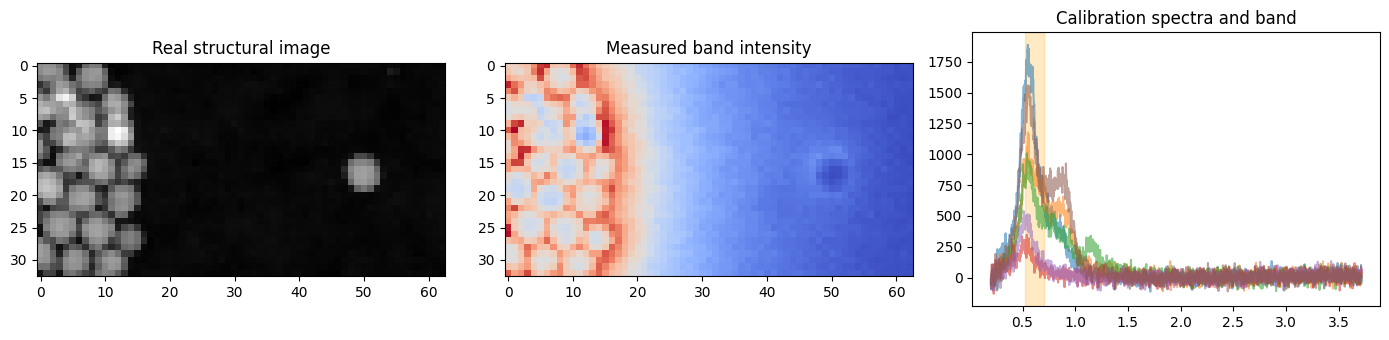

In [26]:
# 2. Intermixed split and source-derived edge-band calibration (never use TEST to select band)
def intermixed_roles(h,w,seed=42,tile=5):
    rr=np.random.default_rng(seed); roles=np.zeros((h,w),np.uint8)
    for y0 in range(0,h,tile):
        for x0 in range(0,w,tile):
            coords=np.array([(y,x) for y in range(y0,min(h,y0+tile)) for x in range(x0,min(w,x0+tile))]);rr.shuffle(coords)
            n=len(coords);nc=round(.2*n);n_test=round(.2*n)
            for j,(y,x) in enumerate(coords):roles[y,x]=1 if j<nc else (3 if j<nc+n_test else 2)
    return roles
ROLE = intermixed_roles(H,W,SEED)
CAL = np.intersect1d(np.flatnonzero((ROLE==1).ravel()), VALID)
POOL = np.intersect1d(np.flatnonzero((ROLE==2).ravel()), VALID)
TEST = np.intersect1d(np.flatnonzero((ROLE==3).ravel()), VALID)
rr=np.random.default_rng(1001); CAL=rr.permutation(CAL)
REF_N=max(50,int(.2*len(CAL))); REF=CAL[:REF_N]; CAL_FIT=CAL[REF_N:]
assert len(np.intersect1d(POOL,TEST))==0
edgegrad=np.hypot(sobel(IMAGE,axis=0),sobel(IMAGE,axis=1)).ravel()
qhi=np.quantile(edgegrad[CAL_FIT],.75);qlo=np.quantile(edgegrad[CAL_FIT],.25)
edge_idx=CAL_FIT[edgegrad[CAL_FIT]>=qhi]
inter_idx=CAL_FIT[edgegrad[CAL_FIT]<=qlo]
contrast=gaussian_filter1d(SRAW[edge_idx].mean(0)-SRAW[inter_idx].mean(0),sigma=max(2,len(ENERGY)//160))
center_idx=int(np.argmax(contrast));hw=max(2,int(.025*len(ENERGY)))
BAND=(float(ENERGY[max(0,center_idx-hw)]),float(ENERGY[min(len(ENERGY)-1,center_idx+hw)]))
mask=(ENERGY>=BAND[0])&(ENERGY<=BAND[1]);assert mask.sum()>=2
YBAND=np.full(NT,np.nan,np.float32)
YBAND[VALID]=np.trapezoid(SRAW[VALID][:,mask],x=ENERGY[mask],axis=1).astype('float32')
ENERGY100=np.linspace(ENERGY[0],ENERGY[-1],100)
YSPEC=np.full((NT,100),np.nan,np.float32)
for idx in VALID: YSPEC[idx]=np.interp(ENERGY100,ENERGY,SRAW[idx])
# Predictor PCA and scaling are fitted using CAL_FIT only; no POOL or hidden TEST labels influence this prior.
PCA_MODEL=PCA(n_components=5,random_state=SEED)
PCA_MODEL.fit(YSPEC[CAL_FIT])
YPC=np.full((NT,5),np.nan,np.float32);YPC[VALID]=PCA_MODEL.transform(YSPEC[VALID])
PC_MEAN=YPC[CAL_FIT].mean(0)
PC_SD=YPC[CAL_FIT].std(0)+1e-6
YPC=(YPC-PC_MEAN)/PC_SD
print('intermixed labels',dict(calfit=len(CAL_FIT),ref=len(REF),pool=len(POOL),test=len(TEST)))
print('Auto-selected band',BAND,'(axis units from source; physical assignment unverified)')
fig,axs=plt.subplots(1,3,figsize=(14,3.5))
axs[0].imshow(IMAGE,cmap='gray');axs[0].set_title('Real structural image')
q=np.full(NT,np.nan);q[VALID]=YBAND[VALID];axs[1].imshow(q.reshape(H,W),cmap='coolwarm');axs[1].set_title('Measured band intensity')
for i in CAL_FIT[:6]:axs[2].plot(ENERGY,SRAW[i],alpha=.55)
axs[2].axvspan(*BAND,color='orange',alpha=.23);axs[2].set_title('Calibration spectra and band')
fig.tight_layout();fig.savefig(OUT/'01_real_data.png',dpi=170);plt.show()


## 2. Physical observation and cost law

A fixed **17 × 17** patch is acquired at requested nominal center \\(\mathbf r\\). The true image center is shifted by instrument drift minus any commanded compensation, and blurred along the fast-scan direction. Time advances during **every** IMAGE, CALIBRATE and SPECTRUM action. The previously used phenomenological blur law is

\\[\sigma(\tau)=\sqrt{(1/\tau-1)/0.12},\quad \tau\in\{0.2,0.3,0.45,0.6,0.8,1\}.\\]

Costs are `3*tau`, `1`, and `1`, respectively. This is a simulated response law, not a measured instrument calibration. The source image and source spectrum are genuine measurements; intermediate shifted **image** pixels use bilinear interpolation and reflected boundaries. The SPECTRUM action selects the nearest *actual measured and eligible* spectral center and logs this discretization. No new spectrum is synthesized.


,tau,image_cost,blur_sigma_px
0,0.20,0.60,5.773503
1,0.30,0.90,4.409586
2,0.45,1.35,3.191424
3,0.60,1.80,2.357023
4,0.80,2.40,1.443376
5,1.00,3.00,0.000000


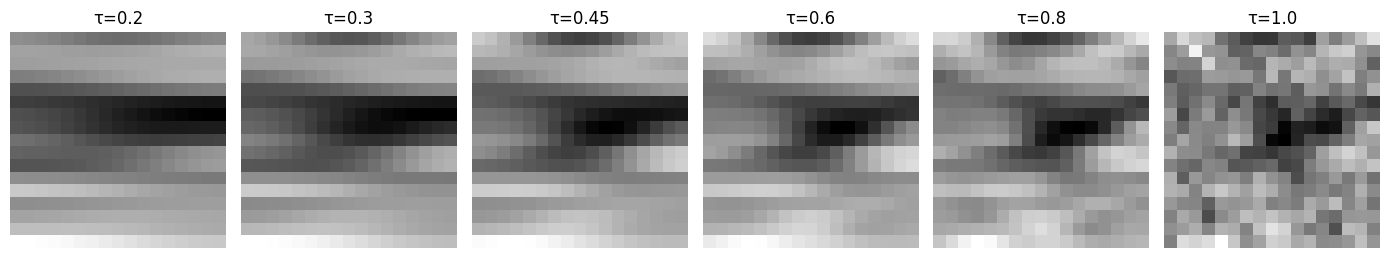

In [27]:
# 3. Physical operators
from torch.nn.functional import adaptive_avg_pool2d
HALF=PATCH//2
GR,GC=np.meshgrid(np.arange(-HALF,HALF+1),np.arange(-HALF,HALF+1),indexing='ij')
def crop_at(pos):
    r,c=np.asarray(pos,float)
    return map_coordinates(IMAGE,[r+GR,c+GC],order=1,mode='reflect').reshape(PATCH,PATCH).astype(np.float32)
def blur_sigma(tau):
    return np.sqrt(max(0.,(1./float(tau)-1.)/.12))
def image_observation(pos,tau):
    sigma=blur_sigma(tau)
    patch=crop_at(pos)
    return patch if sigma < 1e-8 else gaussian_filter1d(patch,sigma,axis=1,mode='reflect')
def pool_features(x,size=7):
    a=np.asarray(x,np.float32)
    if a.ndim==2:a=a[None]
    return adaptive_avg_pool2d(torch.from_numpy(a[:,None]),(size,size)).numpy().reshape(len(a),-1)
# Snapshot of observational costs/blur
scan_table=pd.DataFrame([{'tau':t,'image_cost':3*t,'blur_sigma_px':blur_sigma(t)} for t in TAUS]);display(scan_table)
scan_table.to_csv(OUT/'02_cost_blur_table.csv',index=False)
fig,axs=plt.subplots(1,6,figsize=(14,2.5))
pos=CENTERS[int(POOL[len(POOL)//2])]
for ax,t in zip(axs,TAUS):ax.imshow(image_observation(pos,t),cmap='gray');ax.set_title('τ='+str(t));ax.axis('off')
fig.tight_layout();fig.savefig(OUT/'02_scan_blur_example.png',dpi=160);plt.show()


## 3. Static drift and latent-space damage

The same experimental spectrum remains the target while the feature patch is displaced. The autoencoder is trained on **clean structural patches** and frozen before any drift perturbation. Drift is varied from 0 to 15 pixels. The full gray latent population is shown with two example drift clouds; solid contours represent 0–2, 2–4, …, 8–10 pixel shells. Quantitative measures include normalized kNN target mixing, RMS latent spreading, and the four-model prediction degradation. Note: the 2D embedding is a visualization, not a sufficient statistic for scientific error.


AE epoch 14 MSE 0.2993
AE epoch 28 MSE 0.27503
AE epoch 42 MSE 0.25378
AE epoch 56 MSE 0.24548
AE epoch 70 MSE 0.23933


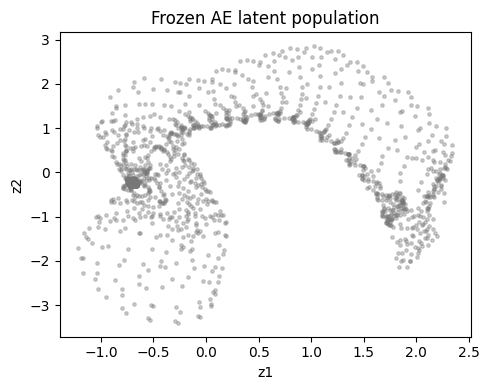

In [28]:
# 4. Clean-trained convolutional autoencoder
class PatchAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc=nn.Sequential(nn.Conv2d(1,12,3,padding=1),nn.ReLU(),nn.AvgPool2d(2),nn.Conv2d(12,24,3,padding=1),nn.ReLU(),nn.AvgPool2d(2),nn.Flatten(),nn.Linear(24*4*4,48),nn.ReLU(),nn.Linear(48,2))
        self.dec=nn.Sequential(nn.Linear(2,48),nn.ReLU(),nn.Linear(48,24*4*4),nn.ReLU(),nn.Unflatten(1,(24,4,4)),nn.Upsample(size=(8,8),mode='bilinear',align_corners=False),nn.Conv2d(24,12,3,padding=1),nn.ReLU(),nn.Upsample(size=(17,17),mode='bilinear',align_corners=False),nn.Conv2d(12,1,3,padding=1))
    def forward(self,x):
        z=self.enc(x);return z,self.dec(z)
AE_TRAIN_IDS=np.random.default_rng(SEED+14).permutation(np.r_[CAL_FIT,POOL])[:min(650,len(CAL_FIT)+len(POOL))]
AE_TEST_IDS=np.random.default_rng(SEED+37).permutation(TEST)[:min(STATIC_TEST_N,len(TEST))]
AE_TRAIN=np.stack([crop_at(CENTERS[i]) for i in AE_TRAIN_IDS])
IM_MEAN=float(AE_TRAIN.mean());IM_STD=float(AE_TRAIN.std()+1e-6)
def ae_tensor(x):return torch.as_tensor((np.asarray(x,np.float32)-IM_MEAN)/IM_STD)[:,None]
ae=PatchAE().to(DEVICE);opt=torch.optim.AdamW(ae.parameters(),lr=.002,weight_decay=1e-5)
loader=DataLoader(TensorDataset(ae_tensor(AE_TRAIN)),batch_size=96,shuffle=True)
AE_HISTORY=[]
for ep in range(AE_EPOCHS):
    ae.train();losses=[]
    for (xb,) in loader:
        xb=xb.to(DEVICE);opt.zero_grad();_,recon=ae(xb);loss=((recon-xb)**2).mean();loss.backward();opt.step();losses.append(float(loss.item()))
    AE_HISTORY.append(np.mean(losses))
    if (ep+1)%max(1,AE_EPOCHS//5)==0:print('AE epoch',ep+1,'MSE',round(AE_HISTORY[-1],5))
ae.eval()
def embed_patches(x):
    z=[]
    with torch.no_grad():
        for batch in ae_tensor(x).split(256):z.append(ae.enc(batch.to(DEVICE)).cpu().numpy())
    return np.vstack(z)
ZTR=embed_patches(AE_TRAIN);ZMU=ZTR.mean(0);ZSD=ZTR.std(0)+1e-6
def embed(ids,delta=(0,0)):
    ids=np.asarray(ids,dtype=int)
    ds=np.asarray(delta,float)
    if ds.ndim==1:ds=np.tile(ds,(len(ids),1))
    x=np.stack([crop_at(CENTERS[i]+d) for i,d in zip(ids,ds)])
    return (embed_patches(x)-ZMU)/ZSD
BG_IDS=VALID;BG_Z=embed(BG_IDS)
TEST_Z0=embed(AE_TEST_IDS)
plt.figure(figsize=(5,4));plt.scatter(BG_Z[:,0],BG_Z[:,1],c='#777',s=6,alpha=.35);plt.title('Frozen AE latent population');plt.xlabel('z1');plt.ylabel('z2');plt.tight_layout();plt.savefig(OUT/'03_clean_latent.png',dpi=170);plt.show()


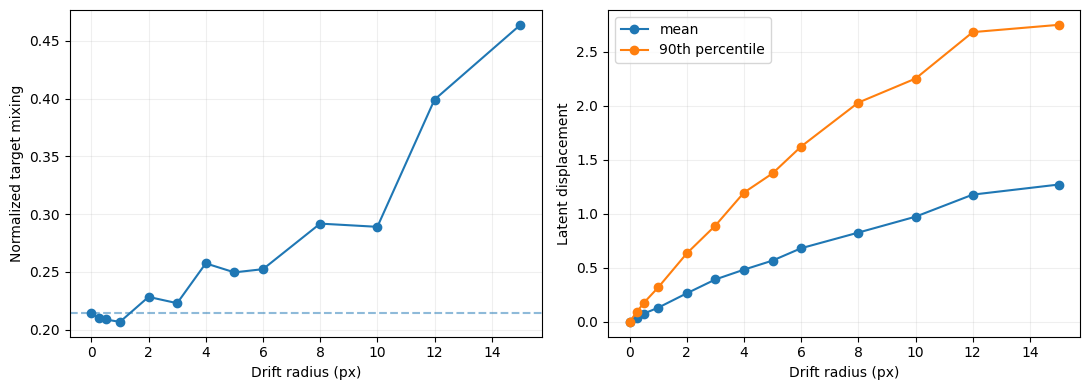

In [29]:
# 5. Global latent mixing and population spreading, 0–15 px
from sklearn.neighbors import NearestNeighbors
TEST_Y=YBAND[AE_TEST_IDS]
def mixing(z,y,k=15):
    k=min(k,len(y)-1)
    ind=NearestNeighbors(n_neighbors=k+1).fit(z).kneighbors(z,return_distance=False)[:,1:]
    return float(np.mean((y[ind]-y[:,None])**2)/(2*np.var(y)+1e-12))
base_mix=mixing(TEST_Z0,TEST_Y)
MIX_ROWS=[];Z_DRIFT={}
for radius in STATIC_DRIFTS:
    theta=np.random.default_rng(303+int(radius*100)).uniform(0,2*np.pi,len(AE_TEST_IDS))
    delta=np.column_stack([radius*np.sin(theta),radius*np.cos(theta)])
    z=embed(AE_TEST_IDS,delta);Z_DRIFT[float(radius)]=z
    shift=np.linalg.norm(z-TEST_Z0,axis=1)
    MIX_ROWS.append(dict(radius=float(radius),mix=mixing(z,TEST_Y),excess_mix=mixing(z,TEST_Y)-base_mix,mean_spread=float(shift.mean()),p90_spread=float(np.quantile(shift,.9))))
mixdf=pd.DataFrame(MIX_ROWS);mixdf.to_csv(OUT/'03_mixing.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(mixdf.radius,mixdf['mix'],'o-');axs[0].axhline(base_mix,ls='--',alpha=.5);axs[0].set_ylabel('Normalized target mixing')
axs[1].plot(mixdf.radius,mixdf.mean_spread,'o-',label='mean');axs[1].plot(mixdf.radius,mixdf.p90_spread,'o-',label='90th percentile');axs[1].legend();axs[1].set_ylabel('Latent displacement')
for ax in axs:ax.set_xlabel('Drift radius (px)');ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT/'03_mixing_and_spread.png',dpi=170);plt.show()


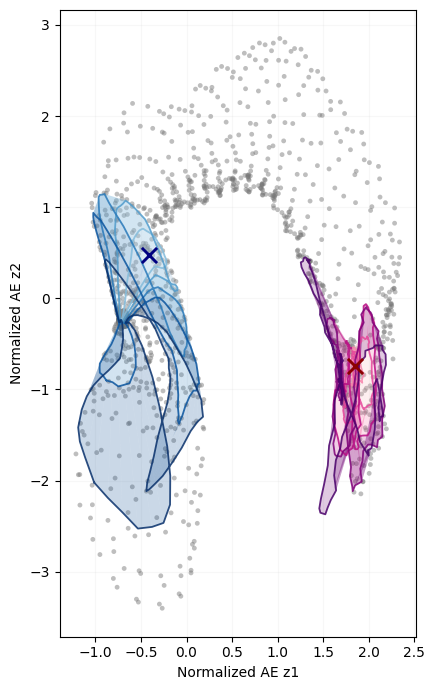

In [30]:
# 6. Two-anchor filled drift contours on gray latent population (0-10 px)
from matplotlib.patches import Polygon
qlo,qhi=np.quantile(TEST_Y,[.1,.9]);lo_ids=AE_TEST_IDS[TEST_Y<=qlo];hi_ids=AE_TEST_IDS[TEST_Y>=qhi]
BLUE=int(lo_ids[np.argmin(abs(YBAND[lo_ids]-np.median(YBAND[lo_ids])))])
RED=int(hi_ids[np.argmin(abs(YBAND[hi_ids]-np.median(YBAND[hi_ids])))])
SHELLS=(0,2,4,6,8,10);angles=np.linspace(0,2*np.pi,N_DRIFT_DIRECTIONS,endpoint=False)
fig,ax=plt.subplots(figsize=(8.6,7))
ax.scatter(BG_Z[:,0],BG_Z[:,1],c='#777777',s=12,alpha=.48,edgecolors='none',zorder=1)
for idx,cmap_name,marker in [(BLUE,'Blues','navy'),(RED,'RdPu','darkred')]:
    cmap=plt.get_cmap(cmap_name);shells={}
    shells[0]=embed([idx])
    for r in SHELLS[1:]:
        dd=np.column_stack([r*np.sin(angles),r*np.cos(angles)])
        shells[r]=embed(np.full(len(angles),idx),dd)
    # Filling between corresponding angular trajectories is a visual convention: boundaries can fold.
    for r0,r1 in zip(SHELLS[:-1],SHELLS[1:]):
        inner=shells[r0];outer=shells[r1]
        for i in range(len(angles)):
            j=(i+1)%len(angles)
            p=np.array([outer[i],outer[j],inner[j] if r0 else inner[0],inner[i] if r0 else inner[0]])
            ax.add_patch(Polygon(p,facecolor=cmap((r0+r1)/20),edgecolor='none',alpha=.21,zorder=2))
    for r in SHELLS[1:]:
        z=shells[r];ax.plot(np.r_[z[:,0],z[0,0]],np.r_[z[:,1],z[0,1]],color=cmap(.3+.7*r/10),lw=1.3,alpha=.85,zorder=3)
    ax.scatter(*shells[0][0],marker='x',s=120,color=marker,lw=2.1,zorder=4)
ax.set_xlabel('Normalized AE z1');ax.set_ylabel('Normalized AE z2');ax.set_aspect('equal',adjustable='box');ax.grid(alpha=.09)
fig.tight_layout();fig.savefig(OUT/'03_filled_drift_clouds.png',dpi=180);plt.show()


## 4. Static regression robustness: Ridge, RF, CNN and DKL

All models are trained on clean registered patches and tested with the **same unchanged experimental spectral labels** but displaced structural inputs. These curves are **static feature misregistration**, not dynamic drift and not registration correction. The DKL below implements a joint learned convolutional feature map and exact GP; its training set is capped for numerical tractability and this fact is logged.


In [31]:
# 7. Model implementations
class CNNReg(nn.Module):
    def __init__(self,outdim):
        super().__init__()
        self.encoder=nn.Sequential(nn.Conv2d(1,12,3,padding=1),nn.ReLU(),nn.AvgPool2d(2),nn.Conv2d(12,24,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d((3,3)),nn.Flatten(),nn.Linear(216,24),nn.Tanh())
        self.head=nn.Linear(24,outdim)
    def forward(self,x):return self.head(self.encoder(x))
def fit_cnn(x,y,epochs,seed=42):
    torch.manual_seed(seed);mean=float(x.mean());sd=float(x.std()+1e-6)
    ym=y.mean(0,keepdims=True);ys=y.std(0,keepdims=True)+1e-6
    tx=torch.as_tensor(((x-mean)/sd)[:,None],dtype=torch.float32)
    ty=torch.as_tensor((y-ym)/ys,dtype=torch.float32)
    model=CNNReg(y.shape[1]).to(DEVICE);opt=torch.optim.AdamW(model.parameters(),lr=.003)
    loader=DataLoader(TensorDataset(tx,ty),batch_size=min(64,len(x)),shuffle=True)
    for ep in range(epochs):
        model.train()
        for xb,yb in loader:
            opt.zero_grad();loss=((model(xb.to(DEVICE))-yb.to(DEVICE))**2).mean();loss.backward();opt.step()
    model.eval();return model,(mean,sd,ym,ys)
def cnn_predict(model,par,x):
    mean,sd,ym,ys=par
    a=torch.as_tensor(((x-mean)/sd)[:,None],dtype=torch.float32)
    with torch.no_grad():p=np.vstack([model(t.to(DEVICE)).cpu().numpy() for t in a.split(256)])
    return p*ys+ym
class DKLPredictor:
    def __init__(self,epochs=30,cap=180):self.epochs=epochs;self.cap=cap
    def fit(self,x,y):
        rr=np.random.default_rng(SEED);take=rr.choice(len(x),min(len(x),self.cap),replace=False)
        x=x[take];y=y[take];self.nfit=len(x)
        self.par=(float(x.mean()),float(x.std()+1e-6),y.mean(0,keepdims=True),y.std(0,keepdims=True)+1e-6)
        xm,xs,ym,ys=self.par
        xx=torch.as_tensor(((x-xm)/xs)[:,None],dtype=torch.float32,device=DEVICE)
        yy=torch.as_tensor((y-ym)/ys,dtype=torch.float32,device=DEVICE)
        self.enc=CNNReg(y.shape[1]).encoder.to(DEVICE)
        self.logl=nn.Parameter(torch.tensor(0.,device=DEVICE));self.logn=nn.Parameter(torch.tensor(-2.,device=DEVICE))
        opt=torch.optim.Adam(list(self.enc.parameters())+[self.logl,self.logn],lr=.008)
        eye=torch.eye(len(xx),device=DEVICE)
        for ep in range(self.epochs):
            opt.zero_grad();z=self.enc(xx)
            k=torch.exp(-torch.cdist(z,z).square()/(2*torch.exp(2*self.logl)))+(torch.exp(self.logn)+1e-4)*eye
            try:L=torch.linalg.cholesky(k)
            except RuntimeError:break
            alpha=torch.cholesky_solve(yy,L)
            obj=(yy*alpha).sum()/(2*yy.shape[1])+torch.log(torch.diagonal(L)).sum()
            obj.backward();opt.step()
        self.xt=xx;self.yt=yy;self.eye=eye;self.enc.eval();return self
    def predict(self,x):
        xm,xs,ym,ys=self.par
        with torch.no_grad():
            z=self.enc(self.xt);K=torch.exp(-torch.cdist(z,z).square()/(2*torch.exp(2*self.logl)))+(torch.exp(self.logn)+1e-4)*self.eye
            ch=torch.linalg.cholesky(K);alpha=torch.cholesky_solve(self.yt,ch)
            xx=torch.as_tensor(((x-xm)/xs)[:,None],dtype=torch.float32,device=DEVICE)
            out=[]
            for batch in xx.split(128):
                zp=self.enc(batch);cross=torch.exp(-torch.cdist(zp,z).square()/(2*torch.exp(2*self.logl)));out.append((cross@alpha).cpu().numpy())
        return np.vstack(out)*ys+ym


DKL training subset 280


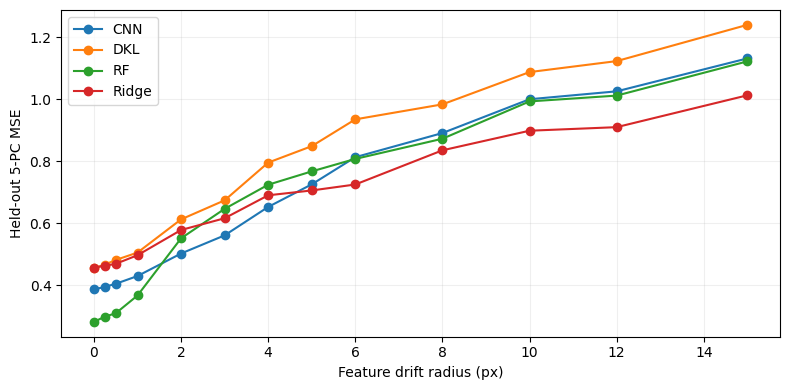

In [32]:
# 8. Static test with the same measured targets across all drift magnitudes
rng=np.random.default_rng(SEED+111)
TR_IDS=rng.permutation(np.r_[CAL_FIT,POOL])[:min(STATIC_TRAIN_N,len(CAL_FIT)+len(POOL))]
TE_IDS=rng.permutation(TEST)[:min(STATIC_TEST_N,len(TEST))]
XTR=np.stack([crop_at(CENTERS[i]) for i in TR_IDS])
YTR=YPC[TR_IDS];YTE=YPC[TE_IDS]
rf=RandomForestRegressor(n_estimators=RF_TREES,min_samples_leaf=2,n_jobs=-1,random_state=SEED)
rf.fit(pool_features(XTR),YTR)
from sklearn.pipeline import make_pipeline
ridge=make_pipeline(StandardScaler(),Ridge(alpha=100.));ridge.fit(pool_features(XTR),YTR)
cnn,cnn_par=fit_cnn(XTR,YTR,CNN_EPOCHS)
dkl=DKLPredictor(DKL_EPOCHS,cap=(280 if MODE=='FULL' else 75)).fit(XTR,YTR)
print('DKL training subset',dkl.nfit)
rows=[]
for radius in STATIC_DRIFTS:
    reps=3 if MODE=='FULL' else 1
    for rep in range(reps):
        rng=np.random.default_rng(10000+rep+int(1000*radius))
        theta=rng.uniform(0,2*np.pi,len(TE_IDS))
        d=np.column_stack([radius*np.sin(theta),radius*np.cos(theta)])
        XT=np.stack([crop_at(CENTERS[i]+dd) for i,dd in zip(TE_IDS,d)])
        preds={'Ridge':ridge.predict(pool_features(XT)),'RF':rf.predict(pool_features(XT)), 'CNN':cnn_predict(cnn,cnn_par,XT),'DKL':dkl.predict(XT)}
        for name,pred in preds.items():rows.append(dict(drift=radius,rep=rep,model=name,mse=np.mean((pred-YTE)**2)))
static_df=pd.DataFrame(rows);static_df.to_csv(OUT/'04_static_model_drift.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4))
for name,g in static_df.groupby('model'):
    m=g.groupby('drift').mse.mean();ax.plot(m.index,m.values,'o-',label=name)
ax.set_xlabel('Feature drift radius (px)');ax.set_ylabel('Held-out 5-PC MSE');ax.legend();ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT/'04_static_model_robustness.png',dpi=170);plt.show()


## 5. Cross-correlation calibration and instrument drift physics

**IMAGE** records the blurred feature patch and advances time. **CALIBRATE** uses that last acquired patch, compares it against the structural reference via normalized cross-correlation, updates drift belief, and issues a position correction; it costs one unit. **After a position correction, a new IMAGE is required before SPECTRUM.** The spectrum action costs one unit and ends the current target. We separately log true absolute targeting error and relative image–spectrum mismatch. Instrument-state estimates are never supplied with oracle true drift.

K1 is a 2D constant-velocity Kalman filter. K2 uses an augmented linear/periodic state with a declared period. This is a structured-model *prior*, favorable in the periodic regime; results must be compared under a matched schedule.


In [33]:
# 9. Drift functions and a Gaussian linear state estimator
class DriftWorld:
    def __init__(self,regime,seed,velocity=.5,period=48.):
        self.regime=regime;self.seed=seed;self.velocity=velocity;self.period=period
        rng=np.random.default_rng(seed);ang=rng.uniform(0,2*np.pi)
        self.v=np.array([np.cos(ang),np.sin(ang)])*velocity
        self.phase=rng.uniform(0,2*np.pi)
        # smooth cumulative stochastic drift, reproducible for any queried time
        self.rng=np.random.default_rng(seed+100000)
        self.knots=np.cumsum(self.rng.normal(scale=.16,size=(2000,2)),axis=0)
    def true(self,t):
        k=min(int(t),len(self.knots)-2); frac=t-k
        rw=self.knots[k]*(1-frac)+self.knots[k+1]*frac
        if self.regime=='random': return rw
        if self.regime=='linear':return self.v*t+rw*.18
        return self.v*t+3.0*np.array([np.sin(2*np.pi*t/self.period+self.phase),np.cos(2*np.pi*t/self.period+self.phase)])+rw*.18
class KalmanBelief:
    def __init__(self,mode='K1',period=48.):
        self.mode=mode;self.period=period;self.t=0.
        self.dim=2 if mode=='K1' else 4
        self.x=np.zeros((2,self.dim));self.P=np.repeat(np.eye(self.dim)[None]*30.,2,axis=0)
    def H(self,t):
        if self.mode=='K1':return np.array([1.,0.])
        return np.array([1.,t,np.sin(2*np.pi*t/self.period),np.cos(2*np.pi*t/self.period)])
    def predict(self,t):
        dt=max(0.,t-self.t)
        if self.mode=='K1':
            F=np.array([[1.,dt],[0.,1.]])
            for j in range(2):
                self.x[j]=F@self.x[j];self.P[j]=F@self.P[j]@F.T+np.diag([.09*dt+.001,.002*dt+.0001])
        else:
            for j in range(2):self.P[j]+=np.diag([.002,.0005,.0002,.0002])*max(dt,.01)
        self.t=t
    def update(self,t,z,measurement_var=.5):
        self.predict(t);H=self.H(t)
        for j in range(2):
            S=float(H@self.P[j]@H+measurement_var);K=self.P[j]@H/S
            self.x[j]+=K*(z[j]-H@self.x[j]);self.P[j]=(np.eye(self.dim)-np.outer(K,H))@self.P[j]
    def estimate(self,t):
        if self.mode=='K1':
            dt=max(0.,t-self.t)
            return np.array([self.x[j,0]+self.x[j,1]*dt for j in range(2)])
        H=self.H(t);return np.array([H@self.x[j] for j in range(2)])
    def uncertainty(self,t):
        if self.mode=='K1':H=np.array([1.,max(0.,t-self.t)])
        else:H=self.H(t)
        return float(np.sqrt(max(0.,sum(H@p@H for p in self.P))))


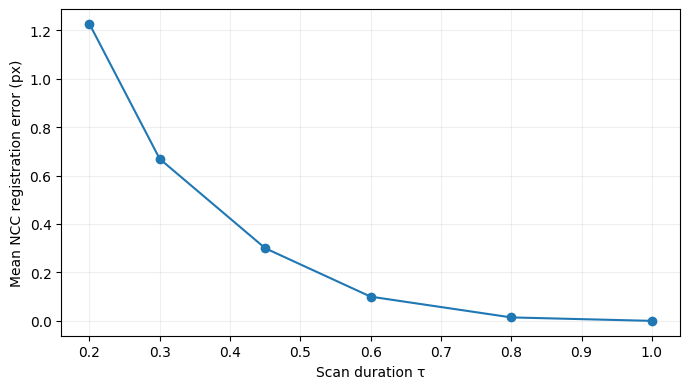

In [34]:
# 10. NCC against reference at shifted centers — estimated registration, not oracle true drift
# Search is limited to +-10 px around the commanded location. The reference is a shared structural survey charged in initialization.
NCC_RANGE=10
NCC_GRID=[(dr,dc) for dr in range(-NCC_RANGE,NCC_RANGE+1,2) for dc in range(-NCC_RANGE,NCC_RANGE+1,2)]
def ncc(a,b):
    x=a-a.mean();y=b-b.mean()
    return float(np.mean(x*y)/(np.std(x)*np.std(y)+1e-8))
def ncc_register(observed,commanded):
    # two-pass search (coarse step2, local step1), using only observed image and known survey
    scores=[]
    for dr,dc in NCC_GRID:
        s=ncc(observed,crop_at(np.asarray(commanded)+np.array([dr,dc])))
        scores.append((s,dr,dc))
    _,br,bc=max(scores)
    fine=[]
    for dr in range(br-1,br+2):
        for dc in range(bc-1,bc+2):fine.append((ncc(observed,crop_at(np.asarray(commanded)+[dr,dc])),dr,dc))
    sorted_scores=sorted(fine,reverse=True)
    score,dr,dc=sorted_scores[0]
    contrast=score-sorted_scores[1][0]
    return np.array([dr,dc],float),float(score),float(contrast)
# Direct blur->registration audit
regr=[];reg_ids=np.random.default_rng(SEED+17).choice(np.r_[CAL_FIT,POOL],size=70 if MODE=='FULL' else 15,replace=False)
for tau in TAUS:
    for i in reg_ids:
        true=np.array([2.,-3.]);obs=image_observation(CENTERS[i]+true,tau)
        pred,peak,margin=ncc_register(obs,CENTERS[i]);regr.append(dict(tau=tau,error=float(np.linalg.norm(pred-true)),peak=peak,contrast=margin))
regdf=pd.DataFrame(regr);regdf.to_csv(OUT/'05_ncc_calibration.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4));ax.plot(regdf.groupby('tau').error.mean(),'o-');ax.set_xlabel('Scan duration τ');ax.set_ylabel('Mean NCC registration error (px)');ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT/'05_ncc_blur_audit.png',dpi=160);plt.show()


## 6. Scientific learner, legal instrument actions and online reward

**Eight actions:** `IMAGE(tau)` for six values, `CALIBRATE` and `SPECTRUM`. The controller may IMAGE repeatedly, then CALIBRATE, then reimage if compensation changed, and eventually SPECTRUM. Only the spectrum produces a supervised pair. A budget constraint makes redundant imaging and calibration costly.

**Discovery reward:** increase in best *actually measured* band integral divided by the seed standard deviation. **Exploration reward:** maturity-weighted decrease in RF tree disagreement on a fixed *paid-for structural reference bank*. Negative uncertainty reductions are retained. Hidden spectral MSE and the full accessible response maximum are used only by the oracle evaluator.

**Important:** model-free RL learns from these realized rewards; Kalman policies use the same observations but an explicit drift belief. A Kalman filter alone is not a policy, so K1/K2 use documented uncertainty-triggered or periodic action rules. We include matched periodic schedules to isolate model effects.


In [35]:
# 11. Fast RF learner with fixed reference images and one training set per campaign
class ScienceLearner:
    def __init__(self,initial_ids,ref_ids,seed=42):
        self.rng=np.random.default_rng(seed)
        self.train_x=[image_observation(CENTERS[i],.8) for i in initial_ids]
        self.train_pc=[YPC[i] for i in initial_ids]
        self.train_band=[float(YBAND[i]) for i in initial_ids]
        self.ref_x=np.stack([image_observation(CENTERS[i],.8) for i in ref_ids]);self.model=None
        self.n_initial=len(initial_ids);self.n_updates=0
        self.record=max(self.train_band)
        self.seed_band_sd=float(np.std(self.train_band)+1e-6)
        self.refit()
    def refit(self):
        self.model=RandomForestRegressor(n_estimators=RF_TREES,min_samples_leaf=2,max_features=.8,n_jobs=1,random_state=SEED)
        self.model.fit(pool_features(np.stack(self.train_x)),np.stack(self.train_pc))
        self.current_U=self.uncertainty(self.ref_x)
    def uncertainty(self,x):
        q=pool_features(x)
        tree=np.stack([t.predict(q) for t in self.model.estimators_])
        return float(np.mean(tree.var(axis=0)))
    def predict_pc(self,x):return self.model.predict(pool_features(x))
    def append(self,image_patch,real_id,force_refit=False):
        oldU=float(self.current_U)
        self.train_x.append(image_patch);self.train_pc.append(YPC[real_id]);self.train_band.append(float(YBAND[real_id]))
        self.n_updates+=1
        oldRecord=self.record;self.record=max(self.record,float(YBAND[real_id]))
        did_refit=force_refit or self.n_updates%RF_REFIT_EVERY==0
        if did_refit:self.refit()
        return {'record_gain':float((self.record-oldRecord)/self.seed_band_sd), 'uncertainty_gain':oldU-float(self.current_U),'did_refit':did_refit}
    def test_mse(self,clean=True):
        ids=TEST;xx=np.stack([crop_at(CENTERS[i]) for i in ids])
        return float(np.mean((self.predict_pc(xx)-YPC[ids])**2))


In [36]:
# 12. Deterministic full-budget environment — actual measured spectra, simulated drift/blur
class EELSEnv:
    def __init__(self,regime,seed,goal='exploit',budget=BUDGET):
        self.regime=regime;self.seed=seed;self.goal=goal;self.budget=float(budget)
        self.world=DriftWorld(regime,seed+1500,velocity=.40,period=48.)
        self.t=0.;self.action_log=[];self.spec_log=[];self.done=False
        self.correct=np.zeros(2);self.belief=None
        self.target_order=np.random.default_rng(seed+700).permutation(POOL)
        self.cursor=0;self.target_id=int(self.target_order[0]);self.last_image=None;self.last_tau=None
        self.requires_new_image=False;self.calibrated=False;self.images_this_target=0
        self.last_cal_time=-999.;self.last_ncc_peak=np.nan
        # independent starting labels are charged from budget, not free
        self.initial_ids=np.random.default_rng(seed+900).choice(CAL_FIT,min(12 if MODE=='FULL' else 4,len(CAL_FIT)),replace=False)
        self.ref_ids=REF[:min(12 if MODE=='FULL' else 4,len(REF))]
        self.science=ScienceLearner(self.initial_ids,self.ref_ids,seed)
        # Paid seed pairs and paid reference-bank images
        init_cost=SURVEY_COST+len(self.initial_ids)*(3*.8+SPEC_COST)+len(self.ref_ids)*3*.8
        self.t=float(init_cost)
        if self.t >= self.budget:raise ValueError('Campaign budget cannot cover paid initialization; increase BUDGET')
        self.initial_cost=init_cost
        self.trace_oracle=[]
    def legal(self):
        if self.done:return []
        choices=[]
        # reserve 1 unit for spectroscopy and allow further imaging only while affordable
        for tau in TAUS:
            if self.t+3*tau+SPEC_COST <= self.budget:choices.append(('IMAGE',tau))
        if self.last_image is not None and not self.requires_new_image and not self.calibrated and self.t+CAL_COST+3*min(TAUS)+SPEC_COST<=self.budget:choices.append(('CALIBRATE',None))
        if self.last_image is not None and not self.requires_new_image and self.t+SPEC_COST<=self.budget:choices.append(('SPECTRUM',None))
        return choices
    def state(self):
        return {'time_left':(self.budget-self.t)/self.budget,'has_image':int(self.last_image is not None),
                'needs_image':int(self.requires_new_image),'images':self.images_this_target,
                'tau':self.last_tau if self.last_tau is not None else 0.,
                'since_cal':min(1.,max(0.,self.t-self.last_cal_time)/40.),
                'n':len(self.science.train_pc),'uncertainty':self.science.current_U,
                'ncc_peak':self.last_ncc_peak if np.isfinite(self.last_ncc_peak) else 0.}
    def act(self,action,belief=None):
        if action not in self.legal():raise ValueError('Illegal action '+str(action)+' time '+str(self.t))
        kind,tau=action;start=self.t;reward=0.;reg_err=np.nan;real_label=None
        target=CENTERS[self.target_id].astype(float)
        if kind=='IMAGE':
            duration=3*tau;self.t+=duration
            pos=target+self.world.true(start+.5*duration)-self.correct
            self.last_image=image_observation(pos,tau);self.last_tau=tau
            self.requires_new_image=False;self.images_this_target+=1;self.last_image_true_pos=pos.copy()
        elif kind=='CALIBRATE':
            # NCC observes the most recent image, anchored to its original command and timestamp.
            rel,peak,contrast=ncc_register(self.last_image,target)
            absolute=rel+self.correct
            obs_time=self.last_image_time if hasattr(self,'last_image_time') else start
            if belief is not None:
                belief.update(obs_time,absolute,measurement_var=max(.05,1-peak))
                est=belief.estimate(self.t+CAL_COST)
            else:est=absolute
            reg_err=float(np.linalg.norm(absolute-self.world.true(obs_time)))
            self.t+=CAL_COST
            self.correct=est.copy();self.last_cal_time=self.t;self.last_ncc_peak=peak
            self.requires_new_image=True;self.calibrated=True
        else:
            self.t+=SPEC_COST
            spectrum_pos=target+self.world.true(self.t)-self.correct
            # Lookup one real experimental spectrum at the closest eligible measured center.
            # The nearest-neighbor quantization is an approximation to shifted beam position;
            allowed=POOL
            loc=CENTERS[allowed];real_label=int(allowed[np.argmin(np.sum((loc-spectrum_pos)**2,axis=1))])
            gain=self.science.append(self.last_image,real_label)
            maturity=len(self.science.train_pc)/(len(self.science.train_pc)+30.)
            reward=gain['record_gain'] if self.goal=='exploit' else maturity*gain['uncertainty_gain']
            self.spec_log.append({'time':self.t,'target_id':self.target_id,'real_id':real_label,
                 'record':self.science.record,'uncertainty':self.science.current_U,
                 'position_error':float(np.linalg.norm(spectrum_pos-target)),
                 'pair_mismatch':float(np.linalg.norm(spectrum_pos-self.last_image_true_pos)),
                 'reward':reward,'n_images':self.images_this_target,'calibrated':self.calibrated,
                 'n':len(self.science.train_pc), 'oracle_hidden_mse':self.science.test_mse() if (self.science.n_updates % (20 if MODE=='FULL' else 10)==0) else np.nan})
            self.cursor+=1
            if self.cursor>=len(self.target_order):self.done=True
            else:self.target_id=int(self.target_order[self.cursor])
            self.last_image=None;self.last_tau=None;self.images_this_target=0
            self.calibrated=False;self.requires_new_image=False
        if kind=='IMAGE': self.last_image_time=self.t
        self.action_log.append({'time_start':start,'time_end':self.t,'action':kind,'tau':tau,
                                'target_id':self.target_id,'reward':reward,
                                'ncc_error':reg_err,'remaining':self.budget-self.t,
                                'goal':self.goal,'regime':self.regime,'seed':self.seed})
        if not self.legal():self.done=True
        return float(reward)


### Important fidelity and evaluation choices

- An image of a given nominal target is *not* an automatically calibrated image. NCC is a separate `CALIBRATE` action.
- The **last acquired image** becomes the feature vector for the current spectrum. A new image after correction is compulsory.
- The full EELS cube provides the spectrum at the **nearest measured eligible center**; the distance to that center should be audited for discretization error. No fractional-pixel spectrum is falsely labeled as measured.
- The current benchmark uses one consistent random candidate order across policies (per seed) to isolate **instrument actions** from spatial acquisition. You can later replace candidate selection with model-based mean or uncertainty scoring, but that is a separate variable.
- Initial seed spectroscopy, fixed reference-image acquisition, and the full structural survey used for NCC are budget-charged. Early operation durations are therefore not comparable to older manuscripts with different initialization charges.


In [37]:
# 13. Baseline controllers, both Kalman beliefs, and policy state bins
def policy_action(env,name,belief=None):
    legal=env.legal();kinds=[a[0] for a in legal]
    if name.startswith('fixed_'):
        tau=float(name.split('_')[1]);candidate=('IMAGE',tau)
        return ('SPECTRUM',None) if 'SPECTRUM' in kinds else (candidate if candidate in legal else legal[0])
    if name=='periodic':
        if env.last_image is None:return ('IMAGE',.6) if ('IMAGE',.6) in legal else legal[0]
        if env.cursor%8==0 and not env.calibrated and 'CALIBRATE' in kinds:return ('CALIBRATE',None)
        if env.requires_new_image:return ('IMAGE',.6) if ('IMAGE',.6) in legal else legal[0]
        return ('SPECTRUM',None)
    if name in ('K1','K2','K1_periodic','K2_periodic'):
        if env.last_image is None or env.requires_new_image:return ('IMAGE',.6) if ('IMAGE',.6) in legal else legal[0]
        periodic_mode=name.endswith('periodic')
        trigger=(env.cursor%8==0) if periodic_mode else (belief.uncertainty(env.t+SPEC_COST) > 2.0 and env.t-env.last_cal_time>4.)
        if trigger and not env.calibrated and 'CALIBRATE' in kinds:return ('CALIBRATE',None)
        return ('SPECTRUM',None)
    raise ValueError(name)
def state_key(s):
    return (int(s['has_image']),int(s['needs_image']),int(s['time_left']*5),
            min(3,int(s['since_cal']*4)),min(3,int(s['images'])),
            int(s['tau']*4),min(4,int(s['n']//35)),int(np.clip(s['uncertainty']*2,0,4)))
ACTIONS=[('IMAGE',t) for t in TAUS]+[('CALIBRATE',None),('SPECTRUM',None)]
class QAgent:
    def __init__(self):self.Q={};self.rng=np.random.default_rng(SEED)
    def qrow(self,key):
        if key not in self.Q:self.Q[key]=np.zeros(len(ACTIONS),float)
        return self.Q[key]
    def choose(self,s,legal,epsilon=0.):
        if self.rng.random()<epsilon:return legal[self.rng.integers(len(legal))]
        q=self.qrow(state_key(s));good=np.array([i for i,a in enumerate(ACTIONS) if a in legal])
        return ACTIONS[int(good[np.argmax(q[good])])]
    def learn(self,s,a,reward,sp,next_legal,done,lr=.12):
        k=state_key(s);q=self.qrow(k);idx=ACTIONS.index(a)
        nxt=0 if done or not next_legal else max(self.qrow(state_key(sp))[ACTIONS.index(ap)] for ap in next_legal)
        q[idx]+=lr*(reward+nxt-q[idx])


In [ ]:
# 14. Train separate model-free Q-learning controllers
# In the model-free baseline, only online acquired images, spectra, rewards and simple action history are observed.
# Kalman state is NOT included in the Q-table.
AGENTS={};TRAIN_LOG=[]
for goal in ('exploit','explore'):
    agent=QAgent()
    for ep in range(N_RL_TRAIN_EPISODES):
        env=EELSEnv(DRIFT_REGIMES[ep%3],seed=20000+ep,goal=goal)
        eps=max(.04,.35*(1-ep/max(1,N_RL_TRAIN_EPISODES)))
        rewards=[];steps=0
        while not env.done and steps<600:
            s=env.state();legal=env.legal()
            if not legal:break
            a=agent.choose(s,legal,epsilon=eps)
            reward=env.act(a);sp=env.state();nlegal=env.legal()
            agent.learn(s,a,reward,sp,nlegal,env.done)
            rewards.append(reward);steps+=1
        TRAIN_LOG.append(dict(goal=goal,episode=ep,return_sum=sum(rewards),n_spectra=len(env.spec_log),steps=steps,states=len(agent.Q)))
        if (ep+1)%max(1,N_RL_TRAIN_EPISODES//5)==0:print(goal,'episode',ep+1,'return',round(sum(rewards),3),'spectra',len(env.spec_log))
    AGENTS[goal]=agent
train_df=pd.DataFrame(TRAIN_LOG);train_df.to_csv(OUT/'06_rl_training.csv',index=False)
fig,ax=plt.subplots(figsize=(8,3.5))
for goal,df in train_df.groupby('goal'):
    ax.plot(df.episode,df.return_sum.rolling(8,min_periods=1).mean(),label=goal)
ax.set_xlabel('Training episode');ax.set_ylabel('Running mean operational return');ax.legend();ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT/'06_rl_training.png',dpi=170);plt.show()


exploit episode 36 return 0.0 spectra 22
exploit episode 72 return 0.0 spectra 34
exploit episode 108 return 0.663 spectra 35
exploit episode 144 return 0.0 spectra 35
exploit episode 180 return 0.0 spectra 35
explore episode 36 return 0.01 spectra 8
explore episode 72 return 0.0 spectra 3


## 7. Full-budget evaluation and frozen-controller comparison

The final test uses held-out *simulated drift seeds* while preserving a fixed set of hidden experimental EELS labels. Q-learning weights are frozen. The primary endpoint is the best acquired band response for exploitation, and the held-out five-PC MSE for structure–property learning. Also report the *opposite* endpoint under each objective. K1 and K2 are compared with both triggered and matched periodic schedules.


In [39]:
# 15. Evaluate all controller families at full budget
POLICIES=['fixed_0.2','fixed_0.6','fixed_1.0','periodic','K1_periodic','K2_periodic','K1','K2','RL']
ENDPOINTS=[];ALL_ACTIONS=[];ALL_SPECTRA=[]
for regime in DRIFT_REGIMES:
    for seed_i in range(N_EVAL_SEEDS):
        world_seed=50000+seed_i+1000*DRIFT_REGIMES.index(regime)
        for goal in ('exploit','explore'):
            for policy in POLICIES:
                env=EELSEnv(regime,world_seed,goal)
                belief=KalmanBelief('K2' if policy.startswith('K2') else 'K1') if policy.startswith('K') else None
                steps=0
                while not env.done and steps<1500:
                    legal=env.legal()
                    if not legal:break
                    if policy=='RL':a=AGENTS[goal].choose(env.state(),legal,epsilon=0.)
                    else:a=policy_action(env,policy,belief)
                    # Some controllers may request impossible action when budget is nearly spent
                    if a not in legal:a=legal[0]
                    env.act(a,belief);steps+=1
                spec=pd.DataFrame(env.spec_log);act=pd.DataFrame(env.action_log)
                key=dict(regime=regime,seed=seed_i,goal=goal,policy=policy)
                count=lambda x:int((act.action==x).sum()) if len(act) else 0
                ENDPOINTS.append({**key,'budget':BUDGET,'time_used':env.t,'initial_cost':env.initial_cost,
                    'best_band':env.science.record,'hidden_pc_mse':env.science.test_mse(),
                    'rf_variance':env.science.current_U,'n_spectra':len(spec),
                    'n_images':count('IMAGE'),'n_calibrations':count('CALIBRATE'),
                    'mean_position_error':float(spec.position_error.mean()) if len(spec) else np.nan,
                    'mean_pair_mismatch':float(spec.pair_mismatch.mean()) if len(spec) else np.nan})
                if len(act):ALL_ACTIONS.append(act.assign(**key))
                if len(spec):ALL_SPECTRA.append(spec.assign(**key))
            print('Completed',regime,'seed',seed_i,'goal',goal,flush=True)
endpoints=pd.DataFrame(ENDPOINTS);actions=pd.concat(ALL_ACTIONS,ignore_index=True);specs=pd.concat(ALL_SPECTRA,ignore_index=True)
endpoints.to_csv(OUT/'07_endpoints.csv',index=False)
actions.to_csv(OUT/'07_actions.csv',index=False)
specs.to_csv(OUT/'07_spectra.csv',index=False)
display(endpoints.groupby(['goal','policy'])[['best_band','hidden_pc_mse','rf_variance','n_spectra','n_calibrations']].agg(['mean','std']).round(3))


Completed random seed 0 goal exploit
Completed random seed 0 goal explore
Completed random seed 1 goal exploit
Completed random seed 1 goal explore
Completed random seed 2 goal exploit
Completed random seed 2 goal explore
Completed random seed 3 goal exploit
Completed random seed 3 goal explore
Completed random seed 4 goal exploit
Completed random seed 4 goal explore
Completed random seed 5 goal exploit
Completed random seed 5 goal explore
Completed random seed 6 goal exploit
Completed random seed 6 goal explore
Completed random seed 7 goal exploit
Completed random seed 7 goal explore
Completed random seed 8 goal exploit
Completed random seed 8 goal explore
Completed random seed 9 goal exploit
Completed random seed 9 goal explore
Completed linear seed 0 goal exploit
Completed linear seed 0 goal explore
Completed linear seed 1 goal exploit
Completed linear seed 1 goal explore
Completed linear seed 2 goal exploit
Completed linear seed 2 goal explore
Completed linear seed 3 goal exploit
C

best_band         hidden_pc_mse        rf_variance         \
                         mean     std          mean    std        mean    std   
goal    policy                                                                  
exploit K1            230.010  23.304         0.937  0.533       0.491  0.152   
        K1_periodic   231.333  27.415         0.941  0.460       0.434  0.169   
        K2            230.046  21.535         0.944  0.559       0.518  0.158   
        K2_periodic   227.631  27.421         0.960  0.491       0.458  0.160   
        RL            224.905  28.584         0.935  0.340       0.523  0.207   
        fixed_0.2     231.546  28.229         0.968  0.440       0.477  0.209   
        fixed_0.6     230.188  27.727         1.031  0.565       0.446  0.203   
        fixed_1.0     230.968  28.044         1.007  0.528       0.471  0.208   
        periodic      226.371  27.028         0.951  0.473       0.444  0.167   
explore K1            230.010  23.304         0.937  0.533       0.491  0.152   
        K1_periodic   231.333  27.415         0.941  0.460       0.434  0.169   
        K2            230.046  21.535         0.944  0.559       0.518  0.158   
        K2_periodic   227.631  27.421         0.960  0.491       0.458  0.160   
        RL            213.483  28.266         0.876  0.185       0.468  0.155   
        fixed_0.2     231.546  28.229         0.968  0.440       0.477  0.209   
        fixed_0.6     230.188  27.727         1.031  0.565       0.446  0.203   
        fixed_1.0     230.968  28.044         1.007  0.528       0.471  0.208   
        periodic      226.371  27.028         0.951  0.473       0.444  0.167   

                    n_spectra         n_calibrations         
                         mean     std           mean    std  
goal    policy                                               
exploit K1             49.567   3.036         30.433  3.036  
        K1_periodic    71.000   0.000          9.000  0.000  
        K2             40.000   0.000         40.000  0.000  
        K2_periodic    71.000   0.000          9.000  0.000  
        RL             46.233  12.987          6.233  5.697  
        fixed_0.2     140.000   0.000          0.000  0.000  
        fixed_0.6      80.000   0.000          0.000  0.000  
        fixed_1.0      56.000   0.000          0.000  0.000  
        periodic       71.000   0.000          9.000  0.000  
explore K1             49.567   3.036         30.433  3.036  
        K1_periodic    71.000   0.000          9.000  0.000  
        K2             40.000   0.000         40.000  0.000  
        K2_periodic    71.000   0.000          9.000  0.000  
        RL              7.933   8.658          2.500  1.776  
        fixed_0.2     140.000   0.000          0.000  0.000  
        fixed_0.6      80.000   0.000          0.000  0.000  
        fixed_1.0      56.000   0.000          0.000  0.000  
        periodic       71.000   0.000          9.000  0.000

In [40]:
# 16. Absolute discovery oracle and empirical predictor reference (NOT a Bayes optimum)
DISCOVERY_CEILING=float(np.nanmax(YBAND[POOL]))
# Full-data RF reference: trained on eligible pool; test labels never enter fitting
oracle_rf=RandomForestRegressor(n_estimators=RF_TREES,min_samples_leaf=2,n_jobs=1,random_state=SEED)
full_x=np.stack([crop_at(CENTERS[i]) for i in POOL]);full_test=np.stack([crop_at(CENTERS[i]) for i in TEST])
oracle_rf.fit(pool_features(full_x),YPC[POOL]);FULL_RF_TEST_MSE=float(np.mean((oracle_rf.predict(pool_features(full_test))-YPC[TEST])**2))
print('Max accessible measured band response:',DISCOVERY_CEILING)
print('Clean full-data RF held-out reference MSE:',FULL_RF_TEST_MSE,'(empirical reference, not intrinsic Bayes risk)')
# Record gap and useful normalized realization fraction per initial condition
startval={}
for regime in DRIFT_REGIMES:
    for seed_i in range(N_EVAL_SEEDS):
        world_seed=50000+seed_i+1000*DRIFT_REGIMES.index(regime)
        init=np.random.default_rng(world_seed+900).choice(CAL_FIT,min(16,len(CAL_FIT)),replace=False)
        startval[(regime,seed_i)]=float(np.max(YBAND[init]))
endpoints['response_regret']=DISCOVERY_CEILING-endpoints.best_band
endpoints['realization_fraction']=[(r.best_band-startval[(r.regime,int(r.seed))])/max(1e-8,DISCOVERY_CEILING-startval[(r.regime,int(r.seed))]) for _,r in endpoints.iterrows()]
endpoints['reference_error_gap']=endpoints.hidden_pc_mse-FULL_RF_TEST_MSE
endpoints.to_csv(OUT/'07_endpoints_oracle.csv',index=False)


Max accessible measured band response: 255.02708435058594
Clean full-data RF held-out reference MSE: 0.23618759201349465 (empirical reference, not intrinsic Bayes risk)


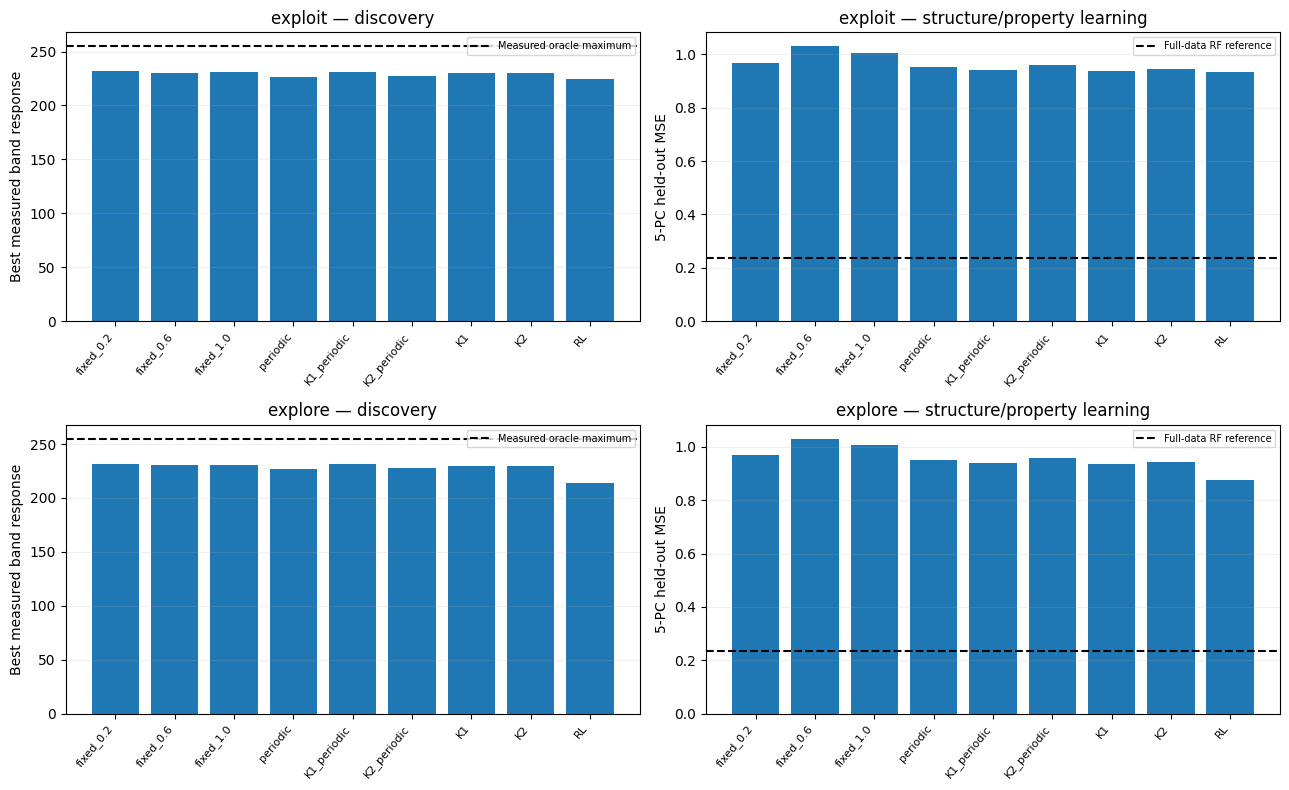

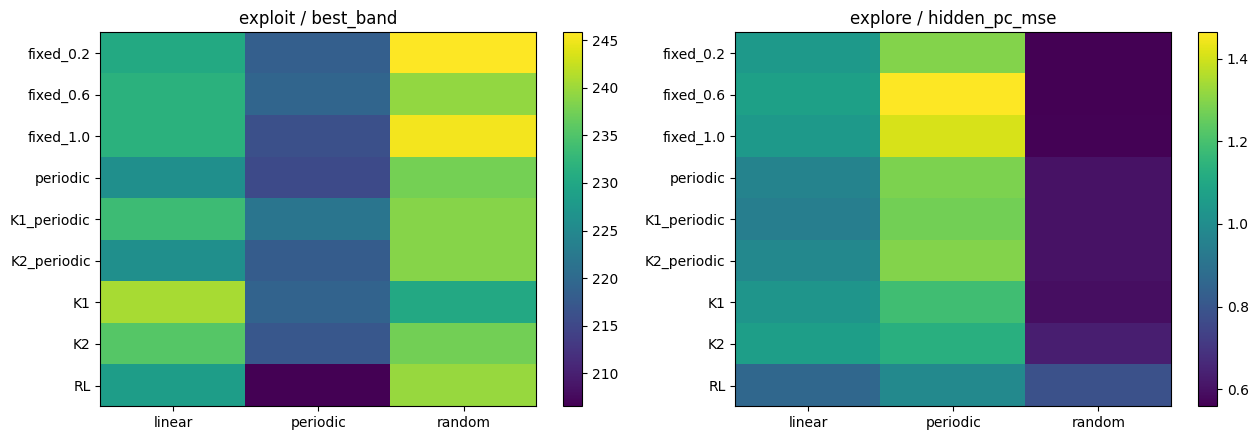

In [41]:
# 17. Aggregate endpoint plots and drift-regime heatmaps
fig,axs=plt.subplots(2,2,figsize=(13,8))
for j,goal in enumerate(('exploit','explore')):
    d=endpoints[endpoints.goal==goal];means=d.groupby('policy',sort=False).mean(numeric_only=True).reindex(POLICIES)
    axs[j,0].bar(np.arange(len(POLICIES)),means.best_band);axs[j,0].axhline(DISCOVERY_CEILING,c='black',ls='--',label='Measured oracle maximum');axs[j,0].set_ylabel('Best measured band response');axs[j,0].set_title(goal+' — discovery');axs[j,0].legend(fontsize=7)
    axs[j,1].bar(np.arange(len(POLICIES)),means.hidden_pc_mse);axs[j,1].axhline(FULL_RF_TEST_MSE,c='black',ls='--',label='Full-data RF reference');axs[j,1].set_ylabel('5-PC held-out MSE');axs[j,1].set_title(goal+' — structure/property learning');axs[j,1].legend(fontsize=7)
    for ax in axs[j]:ax.set_xticks(np.arange(len(POLICIES)),POLICIES,rotation=50,ha='right',fontsize=8);ax.grid(axis='y',alpha=.18)
fig.tight_layout();fig.savefig(OUT/'08_endpoint_comparisons.png',dpi=180);plt.show()
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
for ax,goal,metric in [(axs[0],'exploit','best_band'),(axs[1],'explore','hidden_pc_mse')]:
    mat=endpoints[endpoints.goal==goal].pivot_table(index='policy',columns='regime',values=metric).reindex(POLICIES)
    im=ax.imshow(mat,cmap='viridis',aspect='auto');ax.set_yticks(np.arange(len(POLICIES)),POLICIES);ax.set_xticks(np.arange(3),mat.columns);ax.set_title(goal+' / '+metric);fig.colorbar(im,ax=ax)
fig.tight_layout();fig.savefig(OUT/'08_drift_regime_heatmaps.png',dpi=180);plt.show()


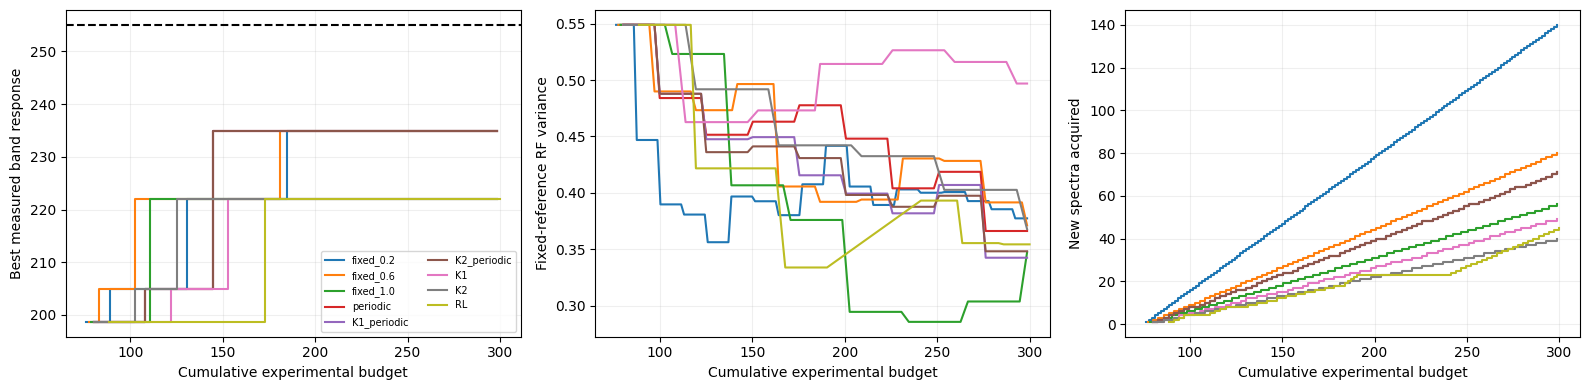

In [42]:
# 18. Time-resolved oracle-realization, RF uncertainty and spectroscopy-throughput curves
sel=specs[(specs.goal=='exploit') & (specs.regime=='periodic') & (specs.seed==0)]
fig,axs=plt.subplots(1,3,figsize=(16,4))
for policy in POLICIES:
    d=sel[sel.policy==policy].sort_values('time')
    if not len(d):continue
    axs[0].step(d.time,d.record,where='post',label=policy)
    axs[1].plot(d.time,d.uncertainty,label=policy)
    axs[2].step(d.time,np.arange(1,len(d)+1),where='post',label=policy)
axs[0].axhline(DISCOVERY_CEILING,c='k',ls='--');axs[0].set_ylabel('Best measured band response')
axs[1].set_ylabel('Fixed-reference RF variance')
axs[2].set_ylabel('New spectra acquired')
for ax in axs:ax.set_xlabel('Cumulative experimental budget');ax.grid(alpha=.2)
axs[0].legend(fontsize=7,ncol=2);fig.tight_layout();fig.savefig(OUT/'09_campaign_learning_curves.png',dpi=180);plt.show()


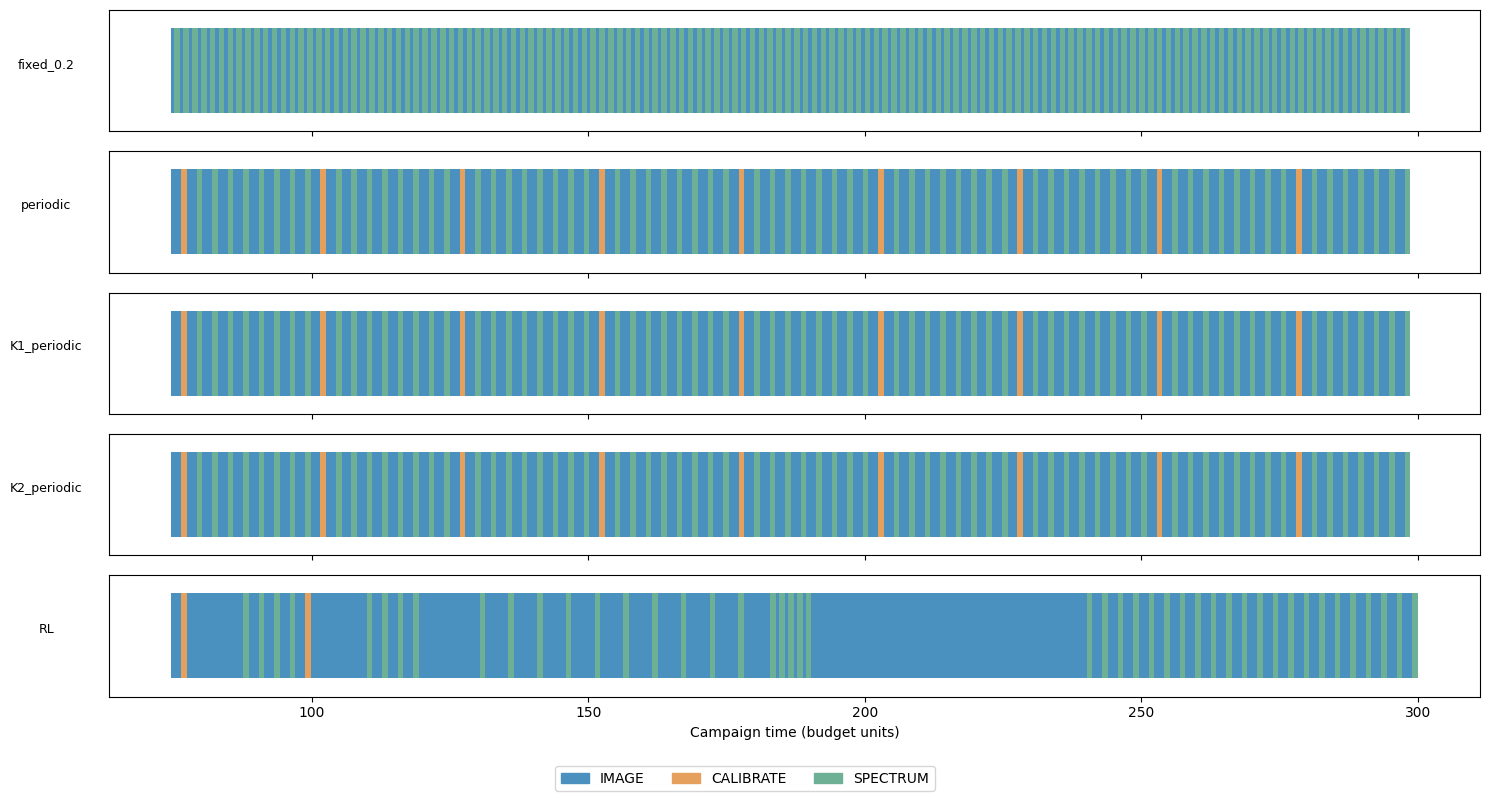

In [43]:
# 19. Representative IMAGE / CALIBRATE / SPECTRUM action timelines and scan-speed histories
from matplotlib.patches import Patch as MplPatch
pols=['fixed_0.2','periodic','K1_periodic','K2_periodic','RL']
sel=actions[(actions.goal=='exploit')&(actions.regime=='periodic')&(actions.seed==0)]
fig,axs=plt.subplots(len(pols),1,figsize=(15,8),sharex=True)
act_colors={'IMAGE':'#4a91bf','CALIBRATE':'#e6a05e','SPECTRUM':'#6eb095'}
for ax,pol in zip(axs,pols):
    d=sel[sel.policy==pol].sort_values('time_start')
    for _,r in d.iterrows():
        ax.broken_barh([(r.time_start,r.time_end-r.time_start)],(0.15,.7),facecolors=act_colors[r.action],edgecolor='none')
    ax.set_ylim(0,1);ax.set_yticks([]);ax.set_ylabel(pol,rotation=0,labelpad=45,fontsize=9)
axs[-1].set_xlabel('Campaign time (budget units)')
fig.legend(handles=[MplPatch(color=c,label=k) for k,c in act_colors.items()],loc='lower center',ncol=3)
fig.tight_layout(rect=(0,.05,1,1));fig.savefig(OUT/'10_action_timelines.png',dpi=180);plt.show()


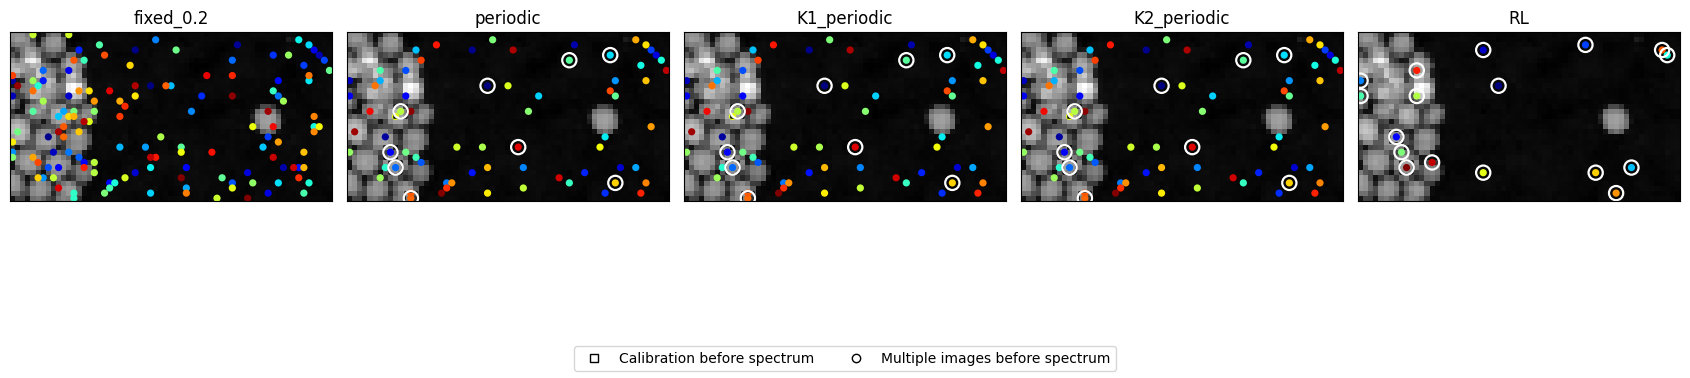

In [44]:
# 20. Figure 11-style spatial exploration trajectories: jet points, squares for CAL, circles for repeated image
from matplotlib.lines import Line2D
pols=['fixed_0.2','periodic','K1_periodic','K2_periodic','RL']
fig,axs=plt.subplots(1,5,figsize=(17,4.7),sharex=True,sharey=True)
for ax,pol in zip(axs,pols):
    d=specs[(specs.goal=='explore')&(specs.regime=='periodic')&(specs.seed==0)&(specs.policy==pol)].sort_values('time')
    ax.imshow(IMAGE,cmap='gray')
    rc=CENTERS[d.target_id.astype(int).to_numpy()] if len(d) else np.empty((0,2))
    order=np.arange(len(d))
    ax.scatter(rc[:,1],rc[:,0],c=order,cmap='jet',vmin=0,vmax=max(1,len(d)-1),s=27,edgecolors='none')
    m=d.calibrated.astype(bool).to_numpy();p=(d.n_images>1).to_numpy()
    ax.scatter(rc[m,1],rc[m,0],marker='s',s=84,facecolors='none',edgecolors='black',linewidths=1.1)
    ax.scatter(rc[p,1],rc[p,0],marker='o',s=105,facecolors='none',edgecolors='white',linewidths=1.6)
    ax.set_title(pol);ax.set_xticks([]);ax.set_yticks([])
fig.legend(handles=[Line2D([0],[0],marker='s',color='k',markerfacecolor='none',ls='None',label='Calibration before spectrum'),Line2D([0],[0],marker='o',color='k',markerfacecolor='none',ls='None',label='Multiple images before spectrum')],loc='lower center',ncol=2)
fig.tight_layout(rect=(0,.1,1,1));fig.savefig(OUT/'11_spatial_exploration.png',dpi=180);plt.show()


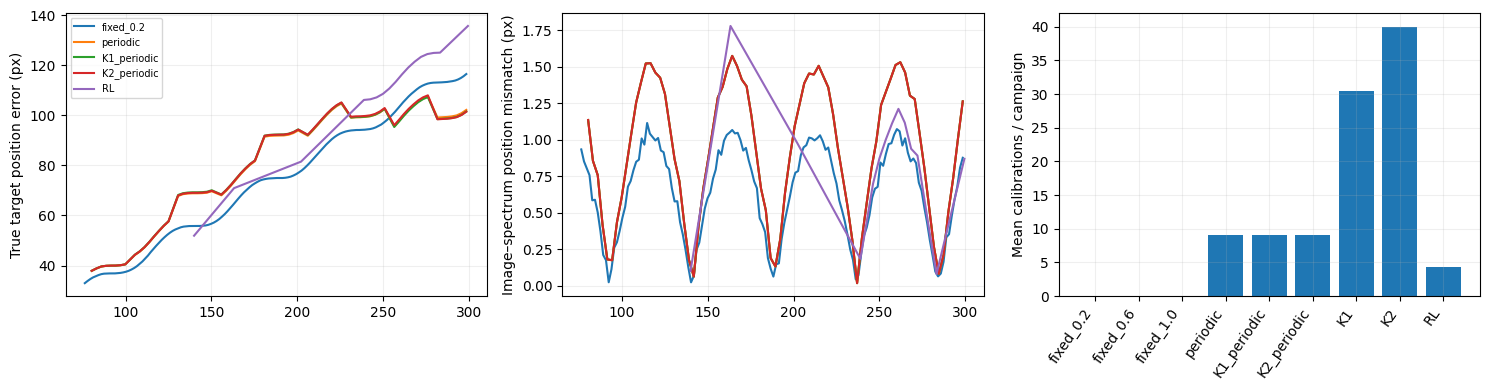

In [45]:
# 21. Position error, image-spectrum mismatch, and cost accounting
fig,axs=plt.subplots(1,3,figsize=(15,4))
sel=specs[(specs.goal=='explore')&(specs.regime=='periodic')&(specs.seed==0)]
for policy in ['fixed_0.2','periodic','K1_periodic','K2_periodic','RL']:
    d=sel[sel.policy==policy].sort_values('time')
    axs[0].plot(d.time,d.position_error,label=policy)
    axs[1].plot(d.time,d.pair_mismatch,label=policy)
axs[0].set_ylabel('True target position error (px)')
axs[1].set_ylabel('Image–spectrum position mismatch (px)')
m=endpoints.groupby('policy').n_calibrations.mean().reindex(POLICIES)
axs[2].bar(np.arange(len(POLICIES)),m);axs[2].set_xticks(range(len(POLICIES)),POLICIES,rotation=55,ha='right');axs[2].set_ylabel('Mean calibrations / campaign')
for ax in axs:ax.grid(alpha=.2)
axs[0].legend(fontsize=7);fig.tight_layout();fig.savefig(OUT/'12_registration_metrology.png',dpi=180);plt.show()


## 8. Independent validation and reproducibility audit

Check that each policy respects its action mask; that a CALIBRATE action follows an IMAGE; that a position-correction requires a new IMAGE before spectroscopy; that each completed target provides at most one spectrum; that the simulation never uses TEST labels to select actions; and that acquisition costs never exceed the configured budget. `SPECTRUM` target lookup always uses a real, eligible spectrum. The absolute response maximum is a measured finite-data ceiling, not a physics/Bayes upper bound. Full-data RF test error is an empirical reference, not a guaranteed attainable limit.


In [46]:
# 22. Audit and export — comprehensive CSVs, figures, and metadata
assert (endpoints.time_used<=BUDGET+1e-6).all()
assert set(actions.action.unique()).issubset({'IMAGE','CALIBRATE','SPECTRUM'})
assert np.isfinite(endpoints.best_band).all() and np.isfinite(endpoints.hidden_pc_mse).all()
# Every spectrum should follow an image, and every calibration after some image
for _,group in actions.groupby(['goal','regime','seed','policy']):
    last_action=None;needs_image=False;has_image=False
    for _,r in group.sort_values('time_end').iterrows():
        if r.action=='IMAGE':has_image=True;needs_image=False
        elif r.action=='CALIBRATE':
            assert has_image, 'Calibration before an image';needs_image=True
        elif r.action=='SPECTRUM':
            assert has_image and not needs_image, 'Spectrum after correction without reimaging'
            has_image=False;needs_image=False
meta={'dataset_key':DATASET_KEY,'source_drive_id':DRIVE_ID,'mode':MODE,'budget':BUDGET,
      'image_shape':list(IMAGE.shape),'n_valid_measured_spectra':len(VALID),'n_test':len(TEST),
      'scan_times':list(TAUS),'image_cost_law':'3*tau','calibration_cost':CAL_COST,'spectrum_cost':SPEC_COST,'common_structural_survey_cost':SURVEY_COST,
      'measured_discovery_ceiling':DISCOVERY_CEILING,'empirical_full_data_RF_MSE':FULL_RF_TEST_MSE,
      'RL_train_episodes_per_goal':N_RL_TRAIN_EPISODES,'evaluation_seeds_per_regime':N_EVAL_SEEDS,
      'limitations':['Synthetic drift/blur; real EELS labels','Nearest measured spectrum for shifted coordinate','Reflected boundaries','K2 specified period is favorable','Fixed spatial candidate order','NCC integer-pixel registration','No live microscope validation']}
(OUT/'manifest.json').write_text(json.dumps(meta,indent=2))
import zipfile
archive=OUT.parent/(OUT.name+'.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for path in OUT.glob('*'):
        if path.is_file():z.write(path,arcname=path.name)
print('Completed full study. Results:',archive)
print('Campaigns evaluated:',len(endpoints),'Actions:',len(actions),'Spectra:',len(specs))


Completed full study. Results: /content/EELS_Complete_Drift_RL_Results.zip
Campaigns evaluated: 540 Actions: 96095 Spectra: 36339


## 9. Interpretation guide

A scientific comparison should inspect **both** target-specific outcomes: record discovery relative to the measured accessible maximum and held-out spectral prediction error relative to the full-data RF reference. Report the average and variability across matched drift seeds and separate random / linear / periodic regimes. Never infer that lower model disagreement guarantees lower prediction error.

The fixed-fast policy may outperform more complicated controllers by collecting more spectra. K1 and K2 may improve positioning but incur imaging/calibration costs; a structured drift model can help drift forecasts but need not improve scientific outcomes. The Q-learning baseline should be reported with training reward curves and held-out policy evaluations; convergence is not guaranteed.

If the original Drive download is unavailable, the notebook intentionally halts and explains how to upload the original file. There is **no synthetic EELS dataset fallback**.